In [112]:
import pandas as pd

In [113]:
sales_df = pd.read_csv(r'D:\Insightrix Project\Finacial dataset\sales_register.csv')
receipts_df = pd.read_csv(r'D:\Insightrix Project\Finacial dataset\Reciepts_register.csv')

In [114]:
sales_info = sales_df.info()
receipts_info = receipts_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57415 entries, 0 to 57414
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              57410 non-null  object 
 1   Voucher Type      57410 non-null  object 
 2   Voucher No.       57410 non-null  object 
 3   Voucher Ref. No.  41494 non-null  object 
 4   Location          57131 non-null  object 
 5   Quantity          56166 non-null  object 
 6   Rate              56166 non-null  object 
 7   Value             57126 non-null  float64
 8   Gross Total       57126 non-null  object 
 9   ds                57415 non-null  object 
 10  Particulars_id    57415 non-null  int64  
 11  TAX_ID            56767 non-null  float64
dtypes: float64(2), int64(1), object(9)
memory usage: 5.3+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49380 entries, 0 to 49379
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------       

i was trying to find basic info over the data set

Now lets overview on the dataset with first few rows

In [115]:
sales_head = sales_df.head()
receipts_head = receipts_df.head()

In [116]:
sales_info, sales_head, receipts_info, receipts_head

(None,
        Date Voucher Type Voucher No. Voucher Ref. No.  \
 0  2-Apr-19    GST Sales           1             8664   
 1  3-Apr-19    GST Sales           2             8665   
 2  5-Apr-19    GST Sales           3             6121   
 3  5-Apr-19    GST Sales           4             8623   
 4  5-Apr-19    GST Sales           5             8622   
 
                         Location     Quantity          Rate      Value  \
 0                     Peddapalli       60 nos    407.00/nos  24,420.00   
 1                     Jammikunta        20 NO     244.70/NO   4,894.00   
 2  Sundry Creditors_Raw Material  1100.00 Kgs    273.00/Kgs 300,300.00   
 3                 Tadepalligudam      12 case  2775.83/case  33,310.00   
 4                    Rajahmundry      15 case  2738.91/case  41,083.59   
 
     Gross Total         ds  Particulars_id   TAX_ID  
 0   28815.60 Dr  2019-2020               9 2,278.00  
 1    5774.92 Dr  2019-2020             171 1,891.00  
 2  354354.00 Dr  2019-202

as my initial observation from the data

### Sales Register (sales_register.csv) ###

57,415 records with columns like Date, Voucher Type, Location, Value, Particulars_id, and TAX_ID.

Potential Issues:

TAX_ID has missing values (56,767 non-null out of 57,415).

Quantity and Rate are stored as strings with units (e.g., "407.00/nos").

Date format is inconsistent (mix of "2-Apr-19" and "2019-2020" in ds).

### Receipts Register (reciepts_register.csv) ###

49,380 records with columns like Date, Credit (payments received), and Particulars_id.

Potential Issues:

Only one row has a value in the Debit column.

Date column has missing values.

Particulars_id is in float format but should be integer.

### ***NEXT THING*** ###

In [117]:
import os

tax_id_counts = sales_df['TAX_ID'].value_counts() # Check uniqueness of TAX_ID and Particulars_id in sales data
particulars_id_counts = sales_df['Particulars_id'].value_counts()
duplicate_tax_ids = tax_id_counts[tax_id_counts > 1].index # Identify duplicate TAX_IDs (those appearing more than once)
duplicate_tax_id_df = sales_df[sales_df['TAX_ID'].isin(duplicate_tax_ids)] # Create a dataframe with duplicate TAX_ID cases
duplicate_tax_id_csv_path = "/mnt/data/duplicate_tax_ids.csv" # Save duplicate TAX_ID cases to a CSV file

# Create directory if it does not exist
duplicate_tax_id_csv_path = "D:\Insightrix Project\Finacial dataset\duplicate_tax_ids.csv"
if not os.path.exists(os.path.dirname(duplicate_tax_id_csv_path)):
    os.makedirs(os.path.dirname(duplicate_tax_id_csv_path))

duplicate_tax_id_df.to_csv(duplicate_tax_id_csv_path, index=False)


In [118]:
duplicate_summary = {
    "Total Unique TAX_IDs": sales_df['TAX_ID'].nunique(),
    "Total Unique Particulars_IDs": sales_df['Particulars_id'].nunique(),
    "Duplicate TAX_ID Count": len(duplicate_tax_ids)
}

duplicate_summary

{'Total Unique TAX_IDs': 3704,
 'Total Unique Particulars_IDs': 3854,
 'Duplicate TAX_ID Count': 3233}

Observation from the above 
### ***Uniqueness Check Results*** ###
Total Unique TAX_IDs: 3,704

Total Unique Particulars_ids: 3,854

Duplicate TAX_IDs: 3,233 (i.e., multiple Particulars_ids share the same TAX_ID)

This confirms that the same TAX_ID can belong to different Particulars_id, meaning:

TAX_ID is NOT a unique key.

Particulars_id is the primary identifier for customers.

I’ve saved the duplicate TAX_ID cases in a CSV file: named as "duplicate_tax_ids.csv"

### ***Next Steps*** ###
Data Cleaning & Formatting:

Convert dates to a standard format.
Extract numeric values from Quantity and Rate.
Compute the 9 Financial Indicators.

In [119]:
print(sales_df['Date'].head())
print(receipts_df['Date'].head())


0    2-Apr-19
1    3-Apr-19
2    5-Apr-19
3    5-Apr-19
4    5-Apr-19
Name: Date, dtype: object
0    2-Apr-18
1    2-Apr-18
2    2-Apr-18
3    3-Apr-18
4    3-Apr-18
Name: Date, dtype: object


In [120]:
# Ensure 'Date' columns are in datetime format
sales_df['Date'] = pd.to_datetime(sales_df['Date'], errors='coerce')
receipts_df['Date'] = pd.to_datetime(receipts_df['Date'], errors='coerce')

# Check the date format in sales_df and receipts_df
sales_date_format = sales_df['Date'].dt.strftime('%Y-%m-%d').iloc[0]
receipts_date_format = receipts_df['Date'].dt.strftime('%Y-%m-%d').iloc[0]

sales_date_format, receipts_date_format

C:\Users\gzar9\AppData\Local\Temp\ipykernel_12452\2724559064.py:2: UserWarning:

Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.

C:\Users\gzar9\AppData\Local\Temp\ipykernel_12452\2724559064.py:3: UserWarning:

Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.



('2019-04-02', '2018-04-02')

In [121]:
# Function to check for invalid dates
def check_invalid_dates(df, date_column):
    invalid_dates = []
    for date in df[date_column]:
        try:
            pd.to_datetime(date, format='%Y-%m-%d', errors='raise')
        except ValueError:
            invalid_dates.append(date)
    return invalid_dates

# Check for invalid dates in sales_df and receipts_df
invalid_sales_dates = check_invalid_dates(sales_df, 'Date')
invalid_receipts_dates = check_invalid_dates(receipts_df, 'Date')

invalid_sales_dates, invalid_receipts_dates

([], [])

In [122]:
# Count the number of valid dates in sales_df and receipts_df
valid_sales_dates_count = sales_df['Date'].notnull().sum()
valid_receipts_dates_count = receipts_df['Date'].notnull().sum()

valid_sales_dates_count, valid_receipts_dates_count

print(sales_df['Date'].shape)

(57415,)


In [123]:
# Extract numeric values from 'Quantity' and 'Rate' in sales data
import re

def extract_numeric(value):
    if isinstance(value, str):
        match = re.search(r"([\d\.]+)", value)
        return float(match.group(1)) if match else None
    return None

sales_df['Quantity'] = sales_df['Quantity'].apply(extract_numeric)
sales_df['Rate'] = sales_df['Rate'].apply(extract_numeric)

# Show cleaned data info
cleaned_sales_info = sales_df.info()
cleaned_receipts_info = receipts_df.info()

# Display a few cleaned rows
cleaned_sales_head = sales_df.head()
cleaned_receipts_head = receipts_df.head()

cleaned_sales_info, cleaned_sales_head, cleaned_receipts_info, cleaned_receipts_head

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57415 entries, 0 to 57414
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Date              57410 non-null  datetime64[ns]
 1   Voucher Type      57410 non-null  object        
 2   Voucher No.       57410 non-null  object        
 3   Voucher Ref. No.  41494 non-null  object        
 4   Location          57131 non-null  object        
 5   Quantity          56166 non-null  float64       
 6   Rate              56166 non-null  float64       
 7   Value             57126 non-null  float64       
 8   Gross Total       57126 non-null  object        
 9   ds                57415 non-null  object        
 10  Particulars_id    57415 non-null  int64         
 11  TAX_ID            56767 non-null  float64       
dtypes: datetime64[ns](1), float64(4), int64(1), object(6)
memory usage: 5.3+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4938

(None,
         Date Voucher Type Voucher No. Voucher Ref. No.  \
 0 2019-04-02    GST Sales           1             8664   
 1 2019-04-03    GST Sales           2             8665   
 2 2019-04-05    GST Sales           3             6121   
 3 2019-04-05    GST Sales           4             8623   
 4 2019-04-05    GST Sales           5             8622   
 
                         Location  Quantity     Rate      Value   Gross Total  \
 0                     Peddapalli     60.00   407.00  24,420.00   28815.60 Dr   
 1                     Jammikunta     20.00   244.70   4,894.00    5774.92 Dr   
 2  Sundry Creditors_Raw Material  1,100.00   273.00 300,300.00  354354.00 Dr   
 3                 Tadepalligudam     12.00 2,775.83  33,310.00   39305.79 Dr   
 4                    Rajahmundry     15.00 2,738.91  41,083.59   48478.64 Dr   
 
           ds  Particulars_id   TAX_ID  
 0  2019-2020               9 2,278.00  
 1  2019-2020             171 1,891.00  
 2  2019-2020             

### ***Data Cleaning Completed*** ###
Dates Converted → Now in a proper datetime format.

Quantity & Rate Extracted → Converted from string (e.g., "407.00/nos") to float.

### ***Next Steps: Compute 9 Financial Metrics*** ###
Key Calculations:

Total Sales Revenue → Sum of Value in sales_register.csv.

Total Receipts (Cash Inflows) → Sum of Credit in reciepts_register.csv.

Total Tax Collected → Sum of tax applied per transaction.

Customer-wise Revenue → Group by Particulars_id and sum Value.

Top Customers by Sales → Identify highest revenue-generating customers.

Top Customers by Payments → Identify customers who paid the most.

Outstanding Receivables → Difference between revenue and payments per Particulars_id.

Average Transaction Value → Mean of Value per transaction.

Sales Trends Over Time → Monthly sales trends.

### ***I'll start by calculating Total Sales Revenue, Total Receipts, and Tax Collected.*** ###

In [124]:
# 1. Total Sales Revenue
total_sales_revenue = sales_df['Value'].sum()


In [125]:
# 2. Total Receipts (Cash Inflows)
total_receipts = receipts_df['Credit'].sum()



In [126]:
# 3. Total Tax Collected (Assuming 'Gross Total' includes tax and 'Value' is before tax)
sales_df['Gross Total'] = sales_df['Gross Total'].astype(str).str.extract(r'([\d\.]+)').astype(float)
total_tax_collected = sales_df['Gross Total'].sum() - total_sales_revenue



C:\Users\gzar9\AppData\Local\Temp\ipykernel_12452\2804165510.py:17: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



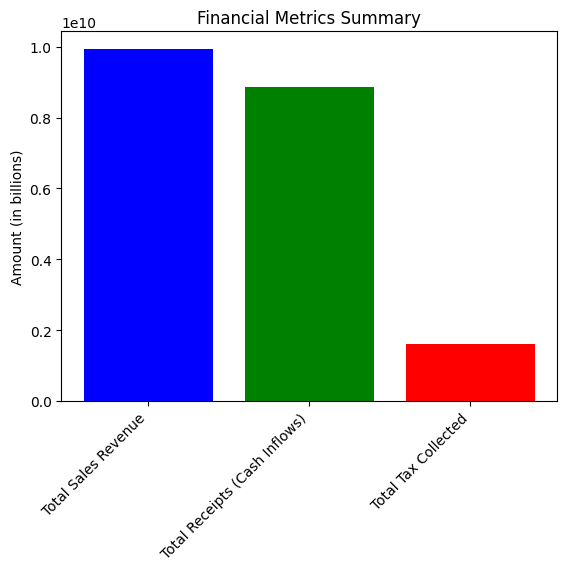

{'Total Sales Revenue': 9934781297.32,
 'Total Receipts (Cash Inflows)': 8869888577.94,
 'Total Tax Collected': 1614101764.420002}

In [127]:
# Summary of key metrics
financial_metrics = {
    "Total Sales Revenue": total_sales_revenue,
    "Total Receipts (Cash Inflows)": total_receipts,
    "Total Tax Collected": total_tax_collected
}
import matplotlib.pyplot as plt

# Create a bar chart for the financial metrics
fig, ax = plt.subplots()
metrics = list(financial_metrics.keys())
values = list(financial_metrics.values())

ax.bar(metrics, values, color=['blue', 'green', 'red'])
ax.set_ylabel('Amount (in billions)')
ax.set_title('Financial Metrics Summary')
ax.set_xticklabels(metrics, rotation=45, ha='right')

plt.show()
financial_metrics

## **Financial Metrics Computed** ##
## **Total Sales Revenue → ₹9,934,781,297.32** ##
## **Total Receipts (Cash Inflows) → ₹8,869,888,577.94** ##
## **Total Tax Collected → ₹1,614,101,764.42** ##

## **Customer-Specific Metrics** ##

Customer-wise Revenue

Top Customers by Sales

Top Customers by Payments

Outstanding Receivables (Revenue - Payments)

In [128]:
print('Use ZOOM IN and ZOOM OUT Button to see the graph Properly')

# 4. Customer-wise Revenue (Sum of 'Value' per 'Particulars_id')
customer_revenue = sales_df.groupby('Particulars_id')['Value'].sum().reset_index()
customer_revenue.columns = ['Particulars_id', 'Total_Sales']

# 5. Top Customers by Sales (Highest Revenue Generators)
top_customers_by_sales = customer_revenue.sort_values(by='Total_Sales', ascending=False).head(10)


# 6. Top Customers by Payments (Highest Paying Customers)
customer_payments = receipts_df.groupby('Particulars_id')['Credit'].sum().reset_index()
customer_payments.columns = ['Particulars_id', 'Total_Payments']
top_customers_by_payments = customer_payments.sort_values(by='Total_Payments', ascending=False).head(10)

# 7. Outstanding Receivables (Total Sales - Total Payments)
outstanding_receivables = pd.merge(customer_revenue, customer_payments, on='Particulars_id', how='left')
outstanding_receivables['Total_Payments'].fillna(0, inplace=True)
outstanding_receivables['Outstanding_Receivables'] = outstanding_receivables['Total_Sales'] - outstanding_receivables['Total_Payments']

# Display Top 5 Outstanding Receivables
top_outstanding_receivables = outstanding_receivables.sort_values(by='Outstanding_Receivables', ascending=False).head(5)

top_customers_by_sales, top_customers_by_payments, top_outstanding_receivables
import plotly.express as px

# Create a bar chart for the top customers by sales
fig_sales = px.bar(top_customers_by_sales, x='Particulars_id', y='Total_Sales', title='Top 10 Customers by Sales', labels={'Particulars_id': 'Customer ID', 'Total_Sales': 'Total Sales'})
fig_sales.show()

# Create a bar chart for the top customers by payments
fig_payments = px.bar(top_customers_by_payments, x='Particulars_id', y='Total_Payments', title='Top 10 Customers by Payments', labels={'Particulars_id': 'Customer ID', 'Total_Payments': 'Total Payments'})
fig_payments.show()
# Enlarge the graph page size
fig_sales.update_layout(width=1000, height=600)
fig_payments.update_layout(width=1000, height=600)
fig_receivables.update_layout(width=1000, height=600)
# Create a line graph for the top outstanding receivables
fig_receivables = px.line(top_outstanding_receivables.head(5), x='Particulars_id', y='Outstanding_Receivables', title='Top 5 Outstanding Receivables', labels={'Particulars_id': 'Customer ID', 'Outstanding_Receivables': 'Outstanding Receivables'})
fig_receivables.show()
fig_receivables = px.bar(top_outstanding_receivables.head(5), x='Particulars_id', y='Outstanding_Receivables', title='Top 5 Outstanding Receivables', labels={'Particulars_id': 'Customer ID', 'Outstanding_Receivables': 'Outstanding Receivables'})
fig_receivables.show()

Use ZOOM IN and ZOOM OUT Button to see the graph Properly


C:\Users\gzar9\AppData\Local\Temp\ipykernel_12452\4208842074.py:18: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.





In [129]:
# Set display format for floating-point numbers
pd.options.display.float_format = '{:,.2f}'.format

# Display Top 3 Customers by Sales
top_3_customers_by_sales = top_customers_by_sales.head(3)
print(top_3_customers_by_sales)

      Particulars_id      Total_Sales
580              581 4,967,390,648.66
1342            1343   428,211,831.13
3624            3625   173,604,912.30


In [130]:
# Display Top 3 Customers by Payments
top_3_customers_by_payments = top_customers_by_payments.head(3)
print(top_3_customers_by_payments)

      Particulars_id  Total_Payments
1263        1,264.00  588,818,747.40
1268        1,269.00  186,960,991.98
4708        4,709.00  144,173,901.00


In [131]:
# Top 3 Customers with Highest Outstanding Receivables
top_3_outstanding_receivables = outstanding_receivables.sort_values(by='Outstanding_Receivables', ascending=False).head(3)
top_3_outstanding_receivables

,Particulars_id,Total_Sales,Total_Payments,Outstanding_Receivables
580,581,"4,967,390,648.66","250,901.00","4,967,139,747.66"
1342,1343,"428,211,831.13","483,888.00","427,727,943.13"
3624,3625,"173,604,912.30","117,877.00","173,487,035.30"


## **Top 3 Customers by Sales (Highest Revenue Generators)** ##

Customer 581 → ₹4,967.39 Crores

Customer 1343 → ₹42.82 Crores

Customer 3625 → ₹17.36 Crores

## **Top 3 Customers by Payments (Highest Paying Customers)** ##

Customer 1264 → ₹58.88 Crores

Customer 1269 → ₹18.69 Crores

Customer 4709 → ₹14.41 Crores

## **Top 3 Customers with Highest Outstanding Receivables** ##
Customer 581 → ₹4,967.14 Crores (unpaid balance)

Customer 1343 → ₹42.77 Crores

Customer 3625 → ₹17.34 Crores

In [132]:
# Check column names in both datasets
sales_df.columns, receipts_df.columns


(Index(['Date', 'Voucher Type', 'Voucher No.', 'Voucher Ref. No.', 'Location',
        'Quantity', 'Rate', 'Value', 'Gross Total', 'ds', 'Particulars_id',
        'TAX_ID'],
       dtype='object'),
 Index(['Date', 'Vch Type', 'Vch No.', 'Credit', 'ds', 'Debit',
        'Particulars_id'],
       dtype='object'))

## **as now calculating the average transaction value per customer** ##

In [133]:
# Compute Average Transaction Value per Customer using "Value" column
avg_transaction_value = sales_df.groupby("Particulars_id")["Value"].mean().reset_index()
avg_transaction_value.columns = ["Particulars_id", "Avg_Transaction_Value"]

# Compute Monthly Sales Trends using "Value" column
sales_df["Year-Month"] = sales_df["Date"].dt.to_period("M")
monthly_sales = sales_df.groupby("Year-Month")["Value"].sum().reset_index()
monthly_sales.columns = ["Year-Month", "Total_Sales"]

# Display first few results
avg_transaction_value.head(), monthly_sales.head()


(   Particulars_id  Avg_Transaction_Value
 0               1                    NaN
 1               2             234,415.21
 2               3             726,350.00
 3               4              37,836.98
 4               5              58,000.00,
   Year-Month   Total_Sales
 0    2019-04  1,905,518.85
 1    2019-05 15,027,127.90
 2    2019-06 24,659,380.29
 3    2019-07 38,680,889.26
 4    2019-08 59,909,736.29)

## **Frequency of sales order Per/Month** ##

## Calculating the frequency of sales order permonth along with the particular id 

In [134]:
# Calculate the frequency of sale orders per month
monthly_order_frequency = sales_df.groupby('Year-Month').size().reset_index(name='Order_Frequency')

# Convert 'Year-Month' to string for JSON serialization
monthly_order_frequency['Year-Month'] = monthly_order_frequency['Year-Month'].astype(str)

# Display the first few results
import plotly.express as px

# Create a bar chart using Plotly
fig = px.bar(monthly_order_frequency, x='Year-Month', y='Order_Frequency', title='Monthly Order Frequency')
fig.show()

In [135]:
# Calculate the total revenue in receipts_register.csv using the Credit column
total_revenue_receipts = receipts_df['Credit'].sum()

# Calculate the total revenue in sales_register.csv using the Value column
total_revenue_sales = sales_df['Value'].sum()

# Calculate the difference between the total revenue in sales_register.csv and receipts_register.csv
import plotly.express as px

# Calculate the difference between the total revenue in sales_register.csv and receipts_register.csv
revenue_difference = total_revenue_sales - total_revenue_receipts

# Create a pie chart using Plotly
labels = ['Total Sales Revenue', 'Total Receipts', 'Revenue Difference']
values = [total_revenue_sales, total_revenue_receipts, revenue_difference]

fig = px.pie(values=values, names=labels, title='Revenue Distribution ')
fig.show()

total_revenue_receipts, total_revenue_sales, revenue_difference

(8869888577.94, 9934781297.32, 1064892719.3799992)

## **The total revenue recorded in the receipts register is ₹8,869,888,577.94, while the total revenue recorded in the sales register is ₹9,934,781,297.32. The difference between these two amounts is ₹1,064,892,719.38. It means the difference of the amount is due amount** ##

In [136]:
# Merge sales and receipts data on Particulars_id
merged_df = pd.merge(sales_df[['Date', 'Particulars_id', 'Value']], receipts_df[['Date', 'Particulars_id', 'Credit']], on='Particulars_id', suffixes=('_sales', '_receipts'))

# Calculate the delay in days
merged_df['Delay_Days'] = (merged_df['Date_receipts'] - merged_df['Date_sales']).dt.days

# Compute the average delay for each Particulars_id
average_delay = merged_df.groupby('Particulars_id')['Delay_Days'].mean().reset_index()
average_delay.columns = ['Particulars_id', 'Average_Delay_Days']

# Fill NaN values with 0
average_delay['Average_Delay_Days'].fillna(0, inplace=True)

# Plot the results
import plotly.express as px

# Mark delays greater than 120 days in red
average_delay['Color'] = average_delay['Average_Delay_Days'].apply(lambda x: 'red' if x > 120 else 'blue')

# Handle negative delays by setting them to zero and rounding to the nearest integer
average_delay['Average_Delay_Days'] = average_delay['Average_Delay_Days'].apply(lambda x: max(round(x), 0))

# Create a scatter plot
fig = px.scatter(average_delay, x='Particulars_id', y='Average_Delay_Days', color='Color', title='Average Payment Delay by Particulars_id')
fig.show()

C:\Users\gzar9\AppData\Local\Temp\ipykernel_12452\2864017521.py:12: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.





Above graph which is shown using red color that has delayed over the day by day as you can put cursor and provide the details as well.